# Evaluation Comparison

Load normalized evaluation artifacts from `data/outputs/runs`, summarize them across runs, compare OxfordEval agreement percentages, and plot GDEX criterion scores for any number of models.

In [5]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

RUNS_DIR = Path("data/outputs/runs")


In [6]:
def load_run_manifest(run_dir: Path) -> dict:
    manifest_path = run_dir / "manifest.json"
    if not manifest_path.exists():
        return {}
    return json.loads(manifest_path.read_text(encoding="utf-8"))


def build_model_label(manifest: dict, run_dir: Path) -> str:
    model = manifest.get("configs", {}).get("model", {})
    model_name = model.get("name")
    model_id = model.get("model_id")
    if model_name and model_id:
        return f"{model_name} ({model_id})"
    if model_name:
        return model_name
    return manifest.get("run_id", run_dir.name)


def load_evaluations(runs_dir: Path = RUNS_DIR) -> pd.DataFrame:
    rows = []
    for eval_path in sorted(runs_dir.glob("*/evaluations.jsonl")):
        run_dir = eval_path.parent
        manifest = load_run_manifest(run_dir)
        model = manifest.get("configs", {}).get("model", {})
        model_label = build_model_label(manifest, run_dir)

        with eval_path.open("r", encoding="utf-8") as handle:
            for line in handle:
                if not line.strip():
                    continue
                row = json.loads(line)
                row["model_label"] = model_label
                row["model_name"] = model.get("name")
                row["model_id"] = model.get("model_id")
                row["has_manifest"] = bool(manifest)
                rows.append(row)

    if not rows:
        return pd.DataFrame()

    return pd.json_normalize(rows)


evaluations_df = load_evaluations()
evaluations_df.head()


,id,run_id,metric_name,metric_config_name,metric_prompt_version,language,lexical_item_id,generated_example_id,score,created_at,...,generator_type,generation_prompt_version,example_text,result.confidence,result.reason,metadata.generated_first,metadata.generated_label,metadata.sentence_a,metadata.sentence_b,provenance.judge_model
0,bedfe535-6f62-4262-8961-2816f6ae2be5,ministral_augmented_eval_v1,oxfordeval,oxfordeval,oxfordeval_1,english,lex-1,gen-1,1.0,2026-03-19T20:24:26.046471Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,a06b84b4-368d-41cb-8791-00a6fc507c2e,mock-eval-run,oxfordeval,oxfordeval,oxfordeval_1,english,lex-001,gen-001,1.0,2026-03-19T19:54:07.306115Z,...,baseline,baseline_v1,She balanced the tray carefully while walking ...,high,Sentence B clearly demonstrates the act of kee...,False,B,Example sentence to change,She balanced the tray carefully while walking ...,gemini-2.5-flash


In [7]:
def summarize_metrics(evaluations: pd.DataFrame) -> pd.DataFrame:
    if evaluations.empty:
        return pd.DataFrame()

    summary = (
        evaluations.groupby(["metric_name", "run_id", "model_label"], dropna=False)
        .agg(
            n=("score", "size"),
            mean_score=("score", "mean"),
        )
        .reset_index()
    )
    summary["agreement_pct"] = summary["mean_score"] * 100
    summary["display_label"] = summary["model_label"] + "\n" + summary["run_id"]
    return summary.sort_values(["metric_name", "agreement_pct"], ascending=[True, False])


metric_summary = summarize_metrics(evaluations_df)
metric_summary


,metric_name,run_id,model_label,n,mean_score,agreement_pct,display_label
0,oxfordeval,ministral_augmented_eval_v1,ministral_qft (Ministral-3B-Instruct),1,1.0,100.0,ministral_qft (Ministral-3B-Instruct)\nministr...
1,oxfordeval,mock-eval-run,mock-eval-run,1,1.0,100.0,mock-eval-run\nmock-eval-run


,run_id,model_label,n,agreement_pct
0,ministral_augmented_eval_v1,ministral_qft (Ministral-3B-Instruct),1,100.0
1,mock-eval-run,mock-eval-run,1,100.0


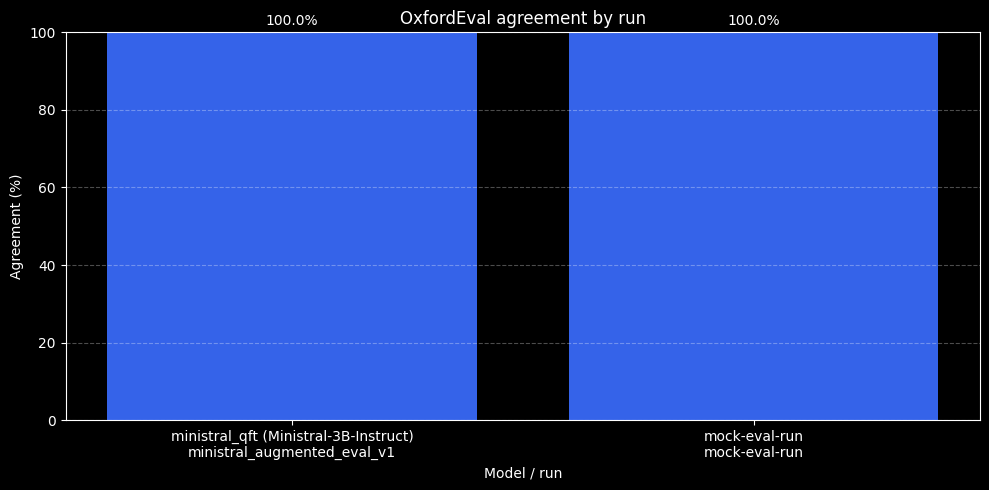

In [8]:
def plot_oxfordeval_agreement(summary: pd.DataFrame) -> pd.DataFrame:
    oxford = summary[summary["metric_name"] == "oxfordeval"].copy()
    if oxford.empty:
        raise ValueError("No OxfordEval rows found in the loaded evaluation artifacts.")

    oxford = oxford.sort_values("agreement_pct", ascending=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(oxford["display_label"], oxford["agreement_pct"], color="#3563E9")
    ax.set_title("OxfordEval agreement by run")
    ax.set_xlabel("Model / run")
    ax.set_ylabel("Agreement (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    for bar, value in zip(bars, oxford["agreement_pct"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.xticks(rotation=0)
    plt.tight_layout()
    return oxford[["run_id", "model_label", "n", "agreement_pct"]]


plot_oxfordeval_agreement(metric_summary)


In [9]:
def summarize_gdex_criteria(evaluations: pd.DataFrame) -> pd.DataFrame:
    gdex = evaluations[evaluations["metric_name"] == "gdex"].copy()
    if gdex.empty:
        return pd.DataFrame()

    criterion_columns = {
        "Typicality": "result.criterion_scores.typical",
        "Informativeness": "result.criterion_scores.informative",
        "Intelligibility": "result.criterion_scores.intelligible",
    }

    missing = [column for column in criterion_columns.values() if column not in gdex.columns]
    if missing:
        raise ValueError(f"Missing GDEX criterion score columns: {missing}")

    rows = []
    for criterion_name, column in criterion_columns.items():
        summary = (
            gdex.groupby(["run_id", "model_label"], dropna=False)[column]
            .mean()
            .reset_index(name="mean_score")
        )
        summary["criterion"] = criterion_name
        rows.append(summary)

    criterion_summary = pd.concat(rows, ignore_index=True)
    criterion_summary["percentage"] = criterion_summary["mean_score"] * 100
    return criterion_summary


gdex_summary = summarize_gdex_criteria(evaluations_df)
gdex_summary


""


In [10]:
def plot_gdex_criteria(summary: pd.DataFrame) -> pd.DataFrame:
    if summary.empty:
        raise ValueError("No GDEX rows found in the loaded evaluation artifacts.")

    criteria_order = ["Typicality", "Informativeness", "Intelligibility"]
    models = summary["model_label"].drop_duplicates().tolist()
    x_positions = list(range(len(criteria_order)))
    width = 0.8 / max(len(models), 1)
    color_map = plt.get_cmap("tab10")

    fig, ax = plt.subplots(figsize=(11, 5))
    for index, model_label in enumerate(models):
        model_rows = (
            summary[summary["model_label"] == model_label]
            .set_index("criterion")
            .reindex(criteria_order)
        )
        offsets = [position - 0.4 + width / 2 + index * width for position in x_positions]
        bars = ax.bar(
            offsets,
            model_rows["percentage"],
            width=width,
            label=model_label,
            color=color_map(index),
        )

        for bar, value in zip(bars, model_rows["percentage"]):
            if pd.notna(value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    value + 1,
                    f"{value:.1f}%",
                    ha="center",
                    va="bottom",
                    fontsize=9,
                )

    ax.set_title("GDEX criterion comparison by model")
    ax.set_xlabel("Criterion")
    ax.set_ylabel("Mean criterion score (%)")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(criteria_order)
    ax.set_ylim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend(title="Model")
    plt.tight_layout()
    return summary.sort_values(["criterion", "percentage"], ascending=[True, False])


plot_gdex_criteria(gdex_summary)


ValueError: No GDEX rows found in the loaded evaluation artifacts.

In [ ]:
def summarize_readability(evaluations: pd.DataFrame) -> pd.DataFrame:
    readability = evaluations[evaluations["metric_name"] == "readability"].copy()
    if readability.empty:
        return pd.DataFrame()

    fkgl_column = "result.fkgl"
    if fkgl_column not in readability.columns:
        raise ValueError("Missing readability FKGL column in evaluation artifacts.")

    summary = (
        readability.groupby(["run_id", "model_label"], dropna=False)
        .agg(
            n=(fkgl_column, "size"),
            mean_fkgl=(fkgl_column, "mean"),
            mean_word_count=("result.word_count", "mean"),
            mean_sentence_count=("result.sentence_count", "mean"),
        )
        .reset_index()
        .sort_values("mean_fkgl")
    )
    summary["display_label"] = summary["model_label"] + "\n" + summary["run_id"]
    return summary


readability_summary = summarize_readability(evaluations_df)
readability_summary


In [ ]:
def plot_readability_fkgl(summary: pd.DataFrame) -> pd.DataFrame:
    if summary.empty:
        raise ValueError("No readability rows found in the loaded evaluation artifacts.")

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(summary["display_label"], summary["mean_fkgl"], color="#2B9348")
    ax.set_title("Readability FKGL by run")
    ax.set_xlabel("Model / run")
    ax.set_ylabel("Mean FKGL")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    for bar, value in zip(bars, summary["mean_fkgl"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
        )

    plt.xticks(rotation=0)
    plt.tight_layout()
    return summary[["run_id", "model_label", "n", "mean_fkgl", "mean_word_count", "mean_sentence_count"]]


plot_readability_fkgl(readability_summary)
